In [1]:
import sys
sys.path.append("../../../../helper_funcs")
from custom_models import *
from tensorflow.keras.callbacks import Callback
from tensorflow.keras import backend as K  # Import the Keras backend
import keras

2025-06-04 17:00:01.618341: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1749049201.631280  114124 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1749049201.635097  114124 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-06-04 17:00:01.648656: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


### (Optional) Force TensorFlow to use the CPU only

In [2]:
#tf.config.set_visible_devices([], 'GPU')

### (Optional) Disable mixed-precision if using GPUs to avoid mismatch in `model.keras` saved model - not a big deal

In [3]:
# from tensorflow.keras.mixed_precision import Policy, set_global_policy

# # Set the precision policy to float32
# policy = Policy('float32')
# set_global_policy(policy)

# # Set deterministic behavior for GPUs and CPUs
# seed = 42
# tf.random.set_seed(seed)
# np.random.seed(seed)
# random.seed(seed)

# tf.config.experimental.enable_op_determinism()

In [4]:
# # Ensure tensorflow backend is using float64 precision
# # Example of setting global precision to float64
# tf.keras.backend.set_floatx('float64')

### Hyperparameters

In [5]:
SCALE=0 # shift (or not) the training data UP. NOTE: it only works with positive values of SCALE, because timestamp values are too close too zero.
EPOCHS=50 # number of training epochs
SINGLE_FILE=0 # if it is ZERO or less, process all files. Otherwise, provide the index of the file (tested on Kaggle dataset only)
OUTPUT_SIZE = 1 # Dense layer output size - which means the number of points predicted. If more than 1, it is considered multi-step prediction.
PATIENCE_REDUCE_LR = 5
PATIENCE_EARLY_STOPPING = 10
FACTOR_REDUCTION = 0.1
TRAIN_SPLIT = 0.7 # % of data for training - between 0.1 and 1.0
VAL_SPLIT = 0.15 # % of data for validation - between 0.1 and 1.0
WEIGHT_DECAY = 1e-4 # if using AdamW
LEARNING_RATE = 0.0001
WINDOW_SIZE = 10 # It determines how many points in the past are taking into account before predicting the next point (a.k.a., timestep)
APPLY_YEO_JOHNSON=False
N = 10000 # first N packets to train

### Import input file(s)

In [6]:
file_path = "data/extracted_csv/DS_Kombat_UL_only.csv"

# Replace 'your_file.csv' with the actual file path
df = pd.read_csv(file_path, header=0)

In [7]:
df

,No.,Time,IPI,Source,Destination,Protocol,Length,Info
0,1,0.000000,0.000000,200.18.102.42,13.104.107.204,RTCP,102,Generic RTP Feedback [Malformed Packet]
1,2,0.004318,0.004318,200.18.102.42,13.104.107.204,DTLSv1.2,151,Application Data
2,21,0.021390,0.017071,200.18.102.42,13.104.107.204,DTLSv1.2,151,Application Data
3,23,0.037535,0.016146,200.18.102.42,13.104.107.204,DTLSv1.2,151,Application Data
4,42,0.050080,0.012544,200.18.102.42,13.104.107.204,RTCP,118,Generic RTP Feedback [Malformed Packet]
...,...,...,...,...,...,...,...,...
23780,392994,299.920807,0.012561,200.18.102.42,13.104.107.204,RTCP,146,Generic RTP Feedback [Malformed Packet]
23781,392995,299.924347,0.003540,200.18.102.42,13.104.107.204,DTLSv1.2,151,Application Data
23782,393040,299.941436,0.017090,200.18.102.42,13.104.107.204,DTLSv1.2,151,Application Data
23783,393041,299.958561,0.017125,200.18.102.42,13.104.107.204,DTLSv1.2,151,Application Data


### Multiply `IPI` column by `1e6`

In [8]:
df['IPI'] *= 1e6

In [9]:
df

,No.,Time,IPI,Source,Destination,Protocol,Length,Info
0,1,0.000000,0.000,200.18.102.42,13.104.107.204,RTCP,102,Generic RTP Feedback [Malformed Packet]
1,2,0.004318,4318.293,200.18.102.42,13.104.107.204,DTLSv1.2,151,Application Data
2,21,0.021390,17071.316,200.18.102.42,13.104.107.204,DTLSv1.2,151,Application Data
3,23,0.037535,16145.833,200.18.102.42,13.104.107.204,DTLSv1.2,151,Application Data
4,42,0.050080,12544.419,200.18.102.42,13.104.107.204,RTCP,118,Generic RTP Feedback [Malformed Packet]
...,...,...,...,...,...,...,...,...
23780,392994,299.920807,12560.954,200.18.102.42,13.104.107.204,RTCP,146,Generic RTP Feedback [Malformed Packet]
23781,392995,299.924347,3539.902,200.18.102.42,13.104.107.204,DTLSv1.2,151,Application Data
23782,393040,299.941436,17089.670,200.18.102.42,13.104.107.204,DTLSv1.2,151,Application Data
23783,393041,299.958561,17124.530,200.18.102.42,13.104.107.204,DTLSv1.2,151,Application Data


### Drop NaN columns

In [10]:
df = df.dropna(axis=1, how='all')
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])
df

,No.,Time,IPI,Source,Destination,Protocol,Length,Info
0,1,0.000000,0.000,200.18.102.42,13.104.107.204,RTCP,102,Generic RTP Feedback [Malformed Packet]
1,2,0.004318,4318.293,200.18.102.42,13.104.107.204,DTLSv1.2,151,Application Data
2,21,0.021390,17071.316,200.18.102.42,13.104.107.204,DTLSv1.2,151,Application Data
3,23,0.037535,16145.833,200.18.102.42,13.104.107.204,DTLSv1.2,151,Application Data
4,42,0.050080,12544.419,200.18.102.42,13.104.107.204,RTCP,118,Generic RTP Feedback [Malformed Packet]
...,...,...,...,...,...,...,...,...
23780,392994,299.920807,12560.954,200.18.102.42,13.104.107.204,RTCP,146,Generic RTP Feedback [Malformed Packet]
23781,392995,299.924347,3539.902,200.18.102.42,13.104.107.204,DTLSv1.2,151,Application Data
23782,393040,299.941436,17089.670,200.18.102.42,13.104.107.204,DTLSv1.2,151,Application Data
23783,393041,299.958561,17124.530,200.18.102.42,13.104.107.204,DTLSv1.2,151,Application Data


### Keep only IPI

In [11]:
df = df[['IPI']]

In [12]:
df

,IPI
0,0.000
1,4318.293
2,17071.316
3,16145.833
4,12544.419
...,...
23780,12560.954
23781,3539.902
23782,17089.670
23783,17124.530


<Axes: >

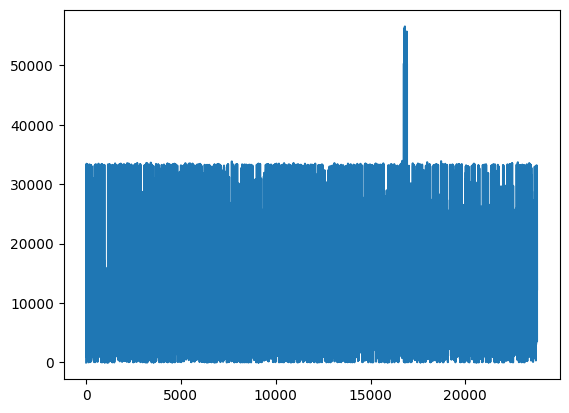

In [13]:
df['IPI'].plot()

### Remove outliers (e.g., 1st and 9th percentile)

<Axes: >

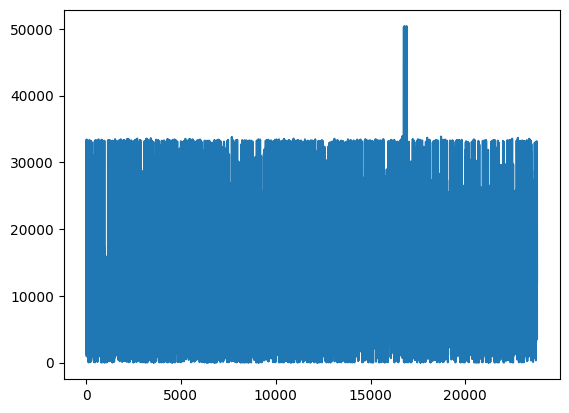

In [14]:
# Function to remove outliers
def remove_outliers(df, columns):
    for col in columns:
        lower_bound = np.percentile(df[col], 0.1)  # 1st percentile
        upper_bound = np.percentile(df[col], 99.9)  # 99th percentile
        df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]  # Filter rows within bounds
    return df

columns_to_check = ['IPI']  # Columns to apply outlier removal
df = remove_outliers(df, columns=columns_to_check)
df['IPI'].plot()

<Axes: >

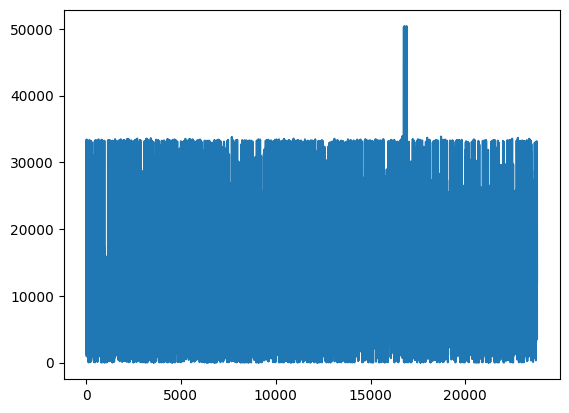

In [15]:
df['IPI'].plot()

### Copy and save remaining packets that will be further used to fill the `window_packets` in the **replacement** script

In [16]:
from sklearn.preprocessing import MinMaxScaler

# Step 1: Save rows from index N+1 onwards into another DataFrame
df_remaining = df.loc[N:, ['IPI']]

print("df_remaining:", df_remaining.head())

# Step 2: Initialize the MinMaxScaler with feature range [-1, 1]
scaler_remaining = MinMaxScaler(feature_range=(-1, 1))

# Step 3: Fit the scaler and transform the data
# Assuming all columns except the index are numeric
scaled_data_remaining = scaler_remaining.fit_transform(df_remaining)

#print("Scaled prediction range:", predictions.min(), predictions.max())
print("Scaler data range:", scaler_remaining.data_min_, scaler_remaining.data_max_)

# Step 4: Create a new DataFrame with the scaled data
df_remaining_scaled = pd.DataFrame(scaled_data_remaining, columns=df_remaining.columns, index=df_remaining.index)

print("df_remaining_scaled:", df_remaining_scaled.head())

# Step 5: Export the scaled DataFrame to a CSV file
df_remaining_scaled.to_csv("packets_N_to_end_scaled_UL.csv", index=False)

# Step 6: Save the scaler_remaining using joblib
joblib.dump(scaler_remaining, "minmax_scaler_remaining_UL.joblib")


df_remaining:              IPI
10000  16119.574
10001   1205.849
10002  15976.016
10003  16050.725
10004  16903.853
Scaler data range: [21.366] [50357.51]
df_remaining_scaled:             IPI
10000 -0.360372
10001 -0.952937
10002 -0.366076
10003 -0.363107
10004 -0.329210


['minmax_scaler_remaining_UL.joblib']

In [17]:
#print("Scaled prediction range:", predictions.min(), predictions.max())
print("Scaler data range:", scaler_remaining.data_min_, scaler_remaining.data_max_)

Scaler data range: [21.366] [50357.51]


<Axes: >

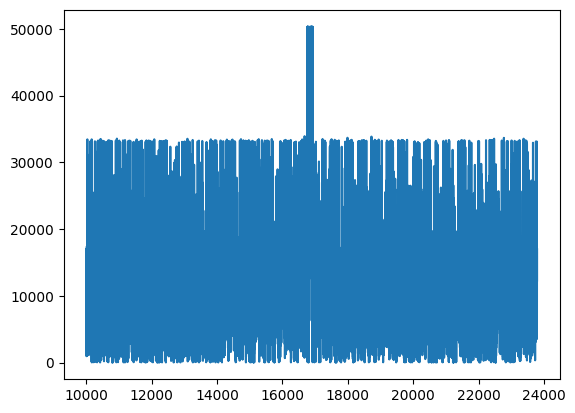

In [18]:
df_remaining['IPI'].plot()

### Get ONLY the first N packets 

In [19]:
df = df.iloc[:N]
df

,IPI
1,4318.293
2,17071.316
3,16145.833
4,12544.419
5,4437.039
...,...
10006,15970.506
10007,15945.584
10008,1796.817
10009,8307.091


In [20]:
# Create lagged features 
# Lagging the IPI_display difference values
# df['lag_1_IPI'] = df['IPI'].shift(1)
# df['lag_2_IPI'] = df['IPI'].shift(2)
# df['lag_3_IPI'] = df['IPI'].shift(3)

# # Rolling window calculations
# df['rolling_mean_IPI'] = df['IPI'].rolling(window=WINDOW_SIZE).mean()
# df['rolling_std_IPI'] = df['IPI'].rolling(window=WINDOW_SIZE).std()
# df['rolling_sum_IPI'] = df['IPI'].rolling(window=WINDOW_SIZE).sum()

# # Lagging the ipv4_ts difference values
# df['lag_1_Length'] = df['Length'].shift(1)
# df['lag_2_Length'] = df['Length'].shift(2)
# df['lag_3_Length'] = df['Length'].shift(3)

# # Rolling window calculations
# df['rolling_mean_Length'] = df['Length'].rolling(window=WINDOW_SIZE).mean()
# df['rolling_std_Length'] = df['Length'].rolling(window=WINDOW_SIZE).std()
# df['rolling_sum_Length'] = df['Length'].rolling(window=WINDOW_SIZE).sum()

# Drop NaN values because of the shift operations
#df = df.dropna()

# selected_manual = ['IPI_display', 'Length', 'stream_id', 'lag_1_IPI_display', 'lag_2_IPI_display', 'lag_3_IPI_display',
#                    'rolling_mean_IPI_display', 'rolling_std_IPI_display', 'lag_1_Length', 'lag_2_Length', 'lag_3_Length',
#                    'rolling_mean_Length', 'rolling_std_Length', 'rolling_sum_Length']

#selected_manual = ['IPI', 'Length', 'stream_id', 'lag_1_IPI', 'lag_2_IPI', 'lag_3_IPI',
#                   'lag_1_Length', 'lag_2_Length', 'lag_3_Length']

#selected_manual = ['IPI', 'Length', 'stream_id']

# selected_manual = ['IPI', 'Length']

# df = df[selected_manual]
# df

In [21]:
#df[['IPI']].plot(subplots=True, layout=(1, 2), figsize=(12, 4), title=['IPI'])

### Split data

In [22]:
def create_complete_windows(group, window_size, target=[], ignored_features=[]):
    """Helper function to create complete windows from a group, excluding specified features from sequences."""
    sequences, targets = [], []
    num_windows = (len(group) - window_size) // window_size  # Count of complete windows

    # Determine feature columns to use for input sequences
    feature_columns = group.columns.difference(ignored_features)

    if num_windows > 0:
        for i in range(num_windows):
            start_idx = i * window_size
            end_idx = start_idx + window_size

            # Append the features (excluding target and ignored features) to sequences
            sequences.append(group.iloc[start_idx:end_idx][feature_columns].to_numpy())

            # Append the target value at 'end_idx' to the targets list
            targets.append(group.iloc[end_idx][target].to_numpy() if len(target) > 1 else group.iloc[end_idx][target])
    
    return sequences, targets

In [23]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import joblib

# Assuming 'df' is your DataFrame
window_size = WINDOW_SIZE
target_columns = ['IPI']  # Specify target columns
ignored_features = []  # Specify ignored features

# Delete 'Class' column because there will be a single class in this case
if 'Class' in df.columns:
    df = df.drop('Class', axis=1)

for col in ignored_features:
    if col in df.columns:
        df = df.drop(col, axis=1)

# First, split into train+test and test sets
train_df, test_df = train_test_split(df, test_size=0.2, shuffle=False, random_state=42)

# Apply MinMaxScaler to each split
scaler = MinMaxScaler(feature_range=(-1, 1))

# Scale and convert back to DataFrame
train_df = pd.DataFrame(scaler.fit_transform(train_df), columns=df.columns)
test_df = pd.DataFrame(scaler.transform(test_df), columns=df.columns)

# Save the MinMaxScaler
joblib.dump(scaler, 'minmax_scaler_UL.joblib')
print("Saved MinMaxScaler to 'minmax_scaler_UL.joblib'.")

# Print scaler parameters
print("Scaler min_ shape:", scaler.min_.shape)
print("Scaler scale_ shape:", scaler.scale_.shape)


# (Testing) 
test_scaler = joblib.load('minmax_scaler_UL.joblib')

# (Testing)
print("(Testing) Scaler min_ shape:", scaler.min_.shape)
print("(Testing) Scaler scale_ shape:", scaler.scale_.shape)


# Create windows for training and testing splits
X_train, y_train = create_complete_windows(train_df, window_size, target=target_columns, ignored_features=ignored_features)
X_test, y_test = create_complete_windows(test_df, window_size, target=target_columns, ignored_features=ignored_features)

# Convert lists to numpy arrays for easier handling with machine learning models
X_train = np.array(X_train)
y_train = np.array(y_train)
X_test = np.array(X_test)
y_test = np.array(y_test)

# Print shapes for verification
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)


Saved MinMaxScaler to 'minmax_scaler_UL.joblib'.
Scaler min_ shape: (1,)
Scaler scale_ shape: (1,)
(Testing) Scaler min_ shape: (1,)
(Testing) Scaler scale_ shape: (1,)
X_train shape: (799, 10, 1)
y_train shape: (799, 1)
X_test shape: (199, 10, 1)
y_test shape: (199, 1)


### Save dataset split

In [24]:
# Save numpy arrays to a compressed .npz file
np.savez_compressed('train_test_splits_UL.npz', 
                    X_train=X_train, y_train=y_train, 
                    X_test=X_test, y_test=y_test)

print("Data saved to 'train_test_splits_UL.npz'.")

Data saved to 'train_test_splits_UL.npz'.


### Load data from npz

In [25]:
# # Load the .npz file
# data = np.load('train_test_splits.npz')

# # Access the arrays
# X_train = data['X_train']
# y_train = data['y_train']
# X_test = data['X_test']
# y_test = data['y_test']

# print("Data loaded successfully.")
# print("X_train shape:", X_train.shape)
# print("y_train shape:", y_train.shape)
# print("X_test shape:", X_test.shape)
# print("y_test shape:", y_test.shape)

### Number of data points after data split

In [26]:
# total rows before split
print(f"Total rows before split:                       {df.shape[0]}")
# total rows after split
print(f"Total rows across all splits (train/val/test): {X_train.shape[0] * X_train.shape[1] + X_test.shape[0] * X_test.shape[1]}")

Total rows before split:                       10000
Total rows across all splits (train/val/test): 9980


In [27]:
import tensorflow as tf
from keras.models import Model
from keras.layers import Input, GRU, Dense, Conv1D, MaxPooling1D, Attention, Flatten, LSTM
from keras.callbacks import ModelCheckpoint
from keras.optimizers import Adam, Nadam
from keras.losses import Huber
from keras.metrics import RootMeanSquaredError
from keras import regularizers
from keras.layers import MultiHeadAttention
from keras.initializers import GlorotUniform, HeNormal, Orthogonal  # Import necessary initializers


def create_model10_temp(output_size=1, window_size=WINDOW_SIZE, num_features=X_test.shape[2], num_rnn_neurons=[128, 64], 
                        filter_sizes=[64, 32], print_summary=False, 
                        loss_func=['mae'], learning_rate=0.001, dropout_rnn=0.25, dropout_window=0,
                        activation_rnn='relu', activation_conv='relu', 
                        activation_dense='tanh', activation_out=None, 
                        l1_reg=0, l2_reg=0.001, conv_kernels=[5, 3], num_dense_neurons=[64, 32], optimizer='Adam',
                        use_layer_norm=False, use_lstm=False, use_attention=True, num_attention_heads=2, stateful=False):
    
    # Define the input layer
    inputs = Input(shape=(window_size, num_features))

    # Add Conv1D and MaxPooling1D layers if conv_kernels list is provided
    # Add Conv1D and MaxPooling1D layers if conv_kernels list is provided
    x = inputs
    if conv_kernels:
        for i, (kernel_size, num_filters) in enumerate(zip(conv_kernels, filter_sizes)):
            if activation_conv == 'relu':
                x = Conv1D(filters=num_filters, kernel_size=kernel_size, padding='same', 
                           activation=activation_conv, kernel_initializer=HeNormal())(x)
            elif activation_conv == 'tanh':
                x = Conv1D(filters=num_filters, kernel_size=kernel_size, padding='same', 
                           activation=activation_conv, kernel_initializer=GlorotUniform())(x)
            else:
                x = Conv1D(filters=num_filters, kernel_size=kernel_size, padding='same', 
                           activation=activation_conv)(x)
            x = BatchNormalization()(x)  # Add batch normalization
            x = MaxPooling1D(pool_size=2)(x)  # Reduce sequence length by half
    else:
        x = inputs  # Skip convolution if add_conv_layers is False

    # Choose between GRU and LSTM based on the use_lstm flag
    rnn_layer = LSTM if use_lstm else GRU


    # Add RNN layers (GRU or LSTM), progressively reducing neuron counts if specified
    for i, neurons in enumerate(num_rnn_neurons[:len(num_rnn_neurons)]):
        return_seq = True if (i < len(num_rnn_neurons) - 1 or use_attention) else False
        if activation_rnn == 'relu':
            x = rnn_layer(neurons, activation=activation_rnn, return_sequences=return_seq,  
                        dropout=dropout_rnn if dropout_rnn > 0 else 0, recurrent_dropout=dropout_window if dropout_window > 0 else 0,
                        kernel_regularizer=regularizers.L1L2(l1=l1_reg, l2=l2_reg) if l1_reg > 0 or l2_reg > 0 else None,
                        kernel_initializer=HeNormal(), stateful=stateful)(x)
        elif activation_rnn == 'tanh':
            x = rnn_layer(neurons, activation=activation_rnn, return_sequences=return_seq,  
                        dropout=dropout_rnn if dropout_rnn > 0 else 0, recurrent_dropout=dropout_window if dropout_window > 0 else 0,
                        kernel_regularizer=regularizers.L1L2(l1=l1_reg, l2=l2_reg) if l1_reg > 0 or l2_reg > 0 else None,
                        kernel_initializer=GlorotUniform(), stateful=stateful)(x)
        else:
            x = rnn_layer(neurons, activation=activation_rnn, return_sequences=return_seq,  
                        dropout=dropout_rnn if dropout_rnn > 0 else 0, recurrent_dropout=dropout_window if dropout_window > 0 else 0,
                        kernel_regularizer=regularizers.L1L2(l1=l1_reg, l2=l2_reg) if l1_reg > 0 or l2_reg > 0 else None,
                        stateful=stateful)(x)
        
        # Apply Layer Normalization after each RNN layer if enabled
        if use_layer_norm:
            x = LayerNormalization()(x)
    
    if use_attention and num_attention_heads > 0 and num_attention_heads <= 1:
        # Use the last output from the GRU as both the query and value
        attention_output = Attention()([x, x])
        x = Flatten()(attention_output)  # Flatten if you plan to use Dense layer

    elif use_attention and num_attention_heads > 1:
        # Use MultiHeadAttention for attention mechanism
        attention_output = MultiHeadAttention(num_heads=num_attention_heads, 
                                              kernel_initializer=Orthogonal(), key_dim=num_rnn_neurons[-1])(x, x)
        
        # You might want to add a skip connection or layer normalization after attention
        x = x + attention_output  # Skip connection
        x = LayerNormalization()(x)  # Optional: add layer normalization

    x = Flatten()(x)  # Flatten if you plan to use Dense layer

    # Add dense layers specified in num_dense_neurons list
    for neurons in num_dense_neurons:
        x = Dense(neurons, activation=activation_dense, kernel_initializer=GlorotUniform())(x)
        x = BatchNormalization()(x)  # Add batch normalization

    # Final Dense output layer
    if activation_out == None:
        outputs = Dense(output_size, activation=None, kernel_initializer=GlorotUniform())(x)
    else:
        outputs = Dense(output_size, activation=activation_out, kernel_initializer=GlorotUniform())(x)

    # Create the model
    model = Model(inputs=inputs, outputs=outputs)

    
    if print_summary:
        model.summary()

    cp = ModelCheckpoint('model10_UL.keras', monitor='loss', mode='min', save_best_only=True)
    if optimizer == 'Adam':
        optimizer = Adam(learning_rate=learning_rate, amsgrad=False)
    elif optimizer == 'AMSgrad':
        optimizer = Adam(learning_rate=learning_rate, amsgrad=True)
    elif optimizer == 'Nadam':
        optimizer = Nadam(learning_rate=learning_rate)
    elif optimizer == 'RMSprop':
        optimizer = RMSprop(learning_rate=learning_rate)
    elif optimizer == 'AdamW':
        optimizer = AdamW(learning_rate=learning_rate)

    model.compile(loss=loss_func, 
                optimizer=optimizer, 
                metrics=['mae'])

    return model, cp

### Force tensorflow to use float64

In [28]:
# # Set the global default data type to float64
#tf.keras.backend.set_floatx('float64')

### Log-Cosh loss - This is a smoother version of the Huber loss that is less sensitive to outliers but still provides gradient information even for small errors

In [29]:
def log_cosh_loss(y_true, y_pred):
    return tf.reduce_mean(tf.math.log(tf.cosh(y_pred - y_true)))

### Epsilon-Insensitive Loss

In [30]:
def epsilon_insensitive_loss(epsilon=0.1):
    """
    Epsilon-insensitive loss function.

    Arguments:
    epsilon -- the threshold below which errors are not penalized (default: 0.1)

    Returns:
    A function that calculates epsilon-insensitive loss.
    """
    def loss(y_true, y_pred):
        error = K.abs(y_true - y_pred)  # Calculate the absolute error
        return K.mean(K.maximum(0.0, error - epsilon))  # Penalize only errors greater than epsilon
    
    return loss

### Mish activation function

In [31]:
def mish(x):
    return x * K.tanh(K.softplus(x))

In [32]:
model10, cp10 = create_model10_temp(
    output_size=1,
    window_size=X_train.shape[1],
    num_features=X_train.shape[2],
    num_rnn_neurons=[128, 128],
    print_summary=True,
    dropout_rnn=0.2,
    dropout_window=0.2,
    loss_func=['mae'],
    activation_rnn=mish,  # Sigmoid for hidden layers (if you want 0-1 output)
    activation_conv='tanh',  # Conv layers with ReLU
    activation_out='tanh',  # Sigmoid for output layers to keep the output between 0-1
    learning_rate=0.0001, # if I increase (e.g., 0.01) I might have more noise
    use_layer_norm=True,
    num_attention_heads=8, # number of attention mechanism heads. ZERO if None
    l1_reg=0.001,
    l2_reg=0.001,
    conv_kernels=[3, 5, 7],
    filter_sizes=[128, 128, 128],
    optimizer='Adam',
    num_dense_neurons=[],
    use_lstm=False,
    use_attention=False,
    activation_dense='tanh', # Sigmoid for dense layers as well
    stateful=False

)


#history10 = model10.fit(X_train, y_train, epochs=10, validation_data=(X_val, y_val), batch_size=32, 
#           callbacks=[plot_predictions_callback_single])

#history10 = model10.fit(X_train, y_train, epochs=10, validation_data=(X_val, y_val), batch_size=32, 
#           callbacks=[plot_predictions_callback_single])


# history10 = model10.fit(X_train, y_train, epochs=20, validation_data=(X_val, y_val), batch_size=32)

#plot_train_and_val_loss(history10)

history10 = model10.fit(X_train, y_train, epochs=50, batch_size=32, callbacks=[cp10])

#plot_train_and_val_loss(history10)

I0000 00:00:1749049204.801088  114124 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5276 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3070, pci bus id: 0000:01:00.0, compute capability: 8.6


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 10, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 10, 128)        │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 10, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 5, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 5, 128)         │        82,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 5, 128)         │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 2, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 2, 128)         │       114,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 2, 128)         │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 1, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 1, 128)         │        99,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization             │ (None, 1, 128)         │           256 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 128)            │        99,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_1           │ (None, 128)            │           256 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 397,697 (1.52 MB)

 Trainable params: 396,929 (1.51 MB)

...

Epoch 1/50


I0000 00:00:1749049209.423262  114236 service.cc:148] XLA service 0x47d9c420 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1749049209.423277  114236 service.cc:156]   StreamExecutor device (0): NVIDIA GeForce RTX 3070, Compute Capability 8.6
2025-06-04 17:00:09.552382: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1749049210.120040  114236 cuda_dnn.cc:529] Loaded cuDNN version 90300
2025-06-04 17:00:12.535386: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_218', 60 bytes spill stores, 64 bytes spill loads



 1/25 ━━━━━━━━━━━━━━━━━━━━ 4:36 12s/step - loss: 6.4103 - mae: 0.6912

I0000 00:00:1749049216.956338  114236 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
2025-06-04 17:00:19.853955: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_218', 32 bytes spill stores, 32 bytes spill loads



25/25 ━━━━━━━━━━━━━━━━━━━━ 19s 312ms/step - loss: 6.3319 - mae: 0.6463
Epoch 2/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 6.0850 - mae: 0.5297 
Epoch 3/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 5.9365 - mae: 0.5070 
Epoch 4/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 5.7813 - mae: 0.4736 
Epoch 5/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 5.6766 - mae: 0.4874 
Epoch 6/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 5.5035 - mae: 0.4296
Epoch 7/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 5.3733 - mae: 0.4122 
Epoch 8/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 5.2205 - mae: 0.3695 
Epoch 9/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 5.1144 - mae: 0.3710 
Epoch 10/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 4.9796 - mae: 0.3415 
Epoch 11/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 4.8549 - mae: 0.3200 
Epoch 12/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 4.7176 - mae: 0.2836 
Epoch 13/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/s

7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 235ms/step
Predictions shape: (199, 1)
Ground truth shape: (199, 1)


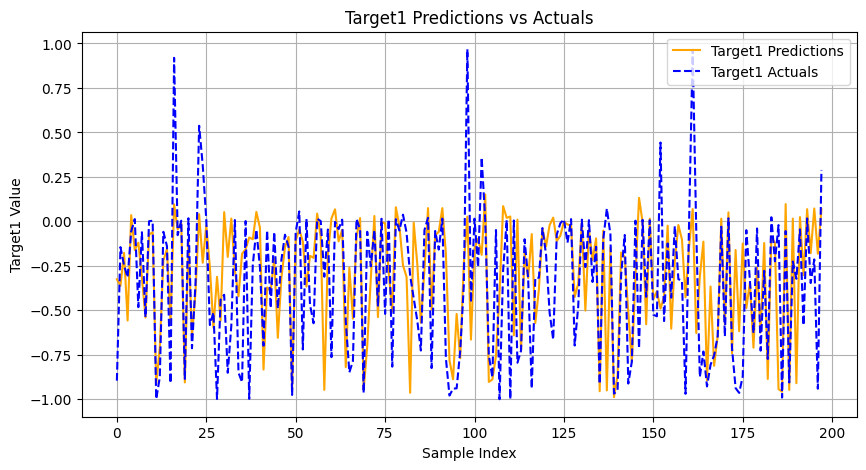

In [33]:
results_df = plot_predictions_generic(model10, X_test, y_test, start=0, end=int(y_test.shape[0]-1), #step=10)
                                        step=int((y_test.shape[0]-1)/100))

In [34]:
predictions = model10.predict(X_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


In [35]:
predictions.shape

(199, 1)

### Save model10 predictions

In [36]:
# Save numpy arrays to a compressed .npz file
np.savez_compressed('model10_predictions_UL.npz', model10_predictions=predictions)

In [37]:
cp10.best

2.2481515407562256

In [38]:
type(cp10.best)

float

### Save and Assert Model

In [39]:
import numpy as np
from keras.models import load_model

# Predict Using Original Model
original_predictions = model10.predict(X_test)

# Save model: if cp10.best is not inf
if np.isinf(cp10.best):
    print("Model saved successfully.")
    model10.save('model10_UL.keras')
else:
    print("Model not saved. Best metric is in callback (cp) - e.g., validation, training, or test loss")

# Save and load model (add custom_objects if needed)
loaded_model = load_model('model10_UL.keras')
loaded_predictions = loaded_model.predict(X_test)

# Compare predictions
diff = np.abs(original_predictions - loaded_predictions)
print("Max difference:", np.max(diff))
print("Mean difference:", np.mean(diff))

# Use a relaxed tolerance
assert np.allclose(original_predictions, loaded_predictions, rtol=1e-5, atol=1e-7), "Mismatch in predictions!"

print("Model verification successful! Predictions are consistent.")

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Model not saved. Best metric is in callback (cp) - e.g., validation, training, or test loss
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 151ms/step
Max difference: 4.172325e-07
Mean difference: 1.07303336e-07


AssertionError: Mismatch in predictions!

In [ ]:
# from keras.utils import plot_model
# from keras.models import load_model
# import sys
# sys.path.append("../../helper_funcs")
# from custom_models import *

# # Step 4: Load the Saved Model
# loaded_model = load_model('model10.keras')
# print("Model loaded successfully from 'model10.keras'.")

# print("Model verification successful! Predictions are consistent.")

# # Assuming 'model' is your Keras model
# plot_model(
# loaded_model,
# to_file="model.png",
# show_shapes=True,
# show_layer_names=True,
# rankdir="TB",
# expand_nested=False,
# show_layer_activations=False,
# dpi=70,
# )